# 03 — Targets: run value por pitch y definiciones de resultado

Stuff+ se entrena contra el **valor en carreras de cada pitch**. Aquí construimos:
1. La tabla de **run expectancy** RE(outs, bolas, strikes) de la LMB.
2. `delta_run_exp` por pitch (el target principal, como en Statcast).
3. Los targets secundarios del reto: whiff, chase, called strike, contacto débil/duro, rolling, out.
4. El **baseline nulo** que pide el jurado: xRunValue promedio por conteo.

**Limitación importante:** no tenemos corredores en base, así que la RE promedia sobre todos los estados de bases.
Para valorar la *calidad del pitch* esto es aceptable (la ocupación de bases no depende del pitch), pero hay que
documentarlo.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data_prep import build_dataset, run_expectancy_table, PROCESSED_PATH, ALTITUDE_ORDER
from src.viz import set_style, savefig, ALT_COLORS, ALT_LABELS, PITCH_ORDER, CAT, INK2, MUTED
set_style(); pd.set_option("display.width", 200)
df = pd.read_parquet(PROCESSED_PATH) if PROCESSED_PATH.exists() else build_dataset(save=True)[0]

## 1. Tabla de run expectancy (LMB 2024–2026)
Carreras esperadas desde antes del pitch hasta el final de la media entrada. Se excluyen las bajas de la 9ª en
adelante (los walk-offs cortan la entrada).

In [2]:
re = run_expectancy_table(df)
re_piv = re.pivot_table(index=["Balls", "Strikes"], columns="Outs", values="re")
re_piv.index = [f"{b}-{s}" for b, s in re_piv.index]
re_piv.columns = [f"{o} outs" for o in re_piv.columns]
assert (re_piv["0 outs"] > re_piv["1 outs"]).all() and (re_piv["1 outs"] > re_piv["2 outs"]).all()
assert re_piv.loc["3-0", "0 outs"] > re_piv.loc["0-2", "0 outs"]
re_piv.round(3)

,0 outs,1 outs,2 outs
0-0,0.889,0.685,0.337
0-1,0.823,0.611,0.284
0-2,0.739,0.543,0.215
1-0,0.949,0.739,0.377
1-1,0.856,0.656,0.319
1-2,0.756,0.558,0.241
2-0,1.061,0.818,0.436
2-1,0.945,0.719,0.371
2-2,0.815,0.587,0.288
3-0,1.277,0.955,0.499


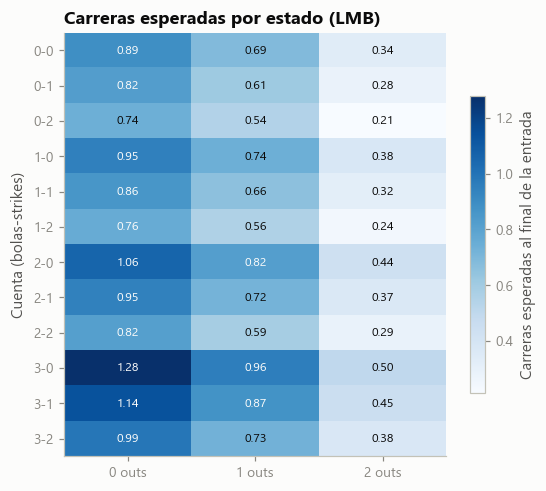

In [3]:
fig, ax = plt.subplots(figsize=(5.6, 5))
im = ax.imshow(re_piv.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels(re_piv.columns)
ax.set_yticks(range(len(re_piv))); ax.set_yticklabels(re_piv.index)
for i in range(re_piv.shape[0]):
    for j in range(3):
        v = re_piv.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="#fcfcfb" if v > 0.75 else "#0b0b0b")
ax.set_ylabel("Cuenta (bolas-strikes)"); ax.grid(False)
ax.set_title("Carreras esperadas por estado (LMB)")
fig.colorbar(im, ax=ax, shrink=0.7, label="Carreras esperadas al final de la entrada")
savefig(fig, "03_run_expectancy"); plt.show()

### ¿Cambia la RE con la altitud?
Si el ambiente ofensivo es distinto, cada estado "vale" distinto. Decisión de diseño para el equipo:
- **RE de liga** (una sola tabla): el valor de un strike es el mismo en todos lados → el Stuff+ mide la calidad del
  pitch en una escala común. *(Recomendado para el target principal.)*
- **RE por ambiente**: útil para traducir a carreras "reales" en Harp Helú.

In [4]:
re_alt = run_expectancy_table(df, by="altitude_category")
sel = re_alt.query("Balls == 0 and Strikes == 0").pivot_table(index="Outs", columns="altitude_category", values="re", observed=True)
sel.columns = [ALT_LABELS[c] for c in sel.columns]
sel.round(3)

,Sin altitud,Altitud media,Altitud extrema
Outs,,,
0,0.730,0.943,1.086
1,0.548,0.768,0.829
2,0.263,0.393,0.405


## 2. Run value por pitch (`delta_run_exp`)
`delta_run_exp = RE(estado siguiente) − RE(estado actual) + carreras anotadas en el pitch`.
Perspectiva del **bateador**: positivo = bueno para la ofensiva. Para el pitcher, negativo es bueno.
Se comprueba en el pipeline que la suma por media entrada = carreras − RE inicial (error ≈ 1e-15).

In [5]:
rv = df.groupby("PitchCall", observed=True).delta_run_exp.agg(["mean", "size"]).sort_values("mean")
rv.columns = ["run value medio", "n"]
rv.round(3)

,run value medio,n
PitchCall,,
StrikeSwinging,-0.129,71914
StrikeCalled,-0.087,97810
FoulBallFieldable,-0.065,1917
FoulBall,-0.054,2799
FoulBallNotFieldable,-0.054,104081
Undefined,-0.019,841
InPlay,0.013,115946
BallCalled,0.054,226061
HitByPitch,0.059,2280


In [6]:
inplay = df[df.in_play]
rv_res = inplay.groupby("play_result", observed=True).delta_run_exp.agg(["mean", "size"]).query("size > 100").sort_values("mean")
rv_res.columns = ["run value medio", "n"]
rv_res.round(3)

,run value medio,n
play_result,,
Out,-0.275,66920
FieldersChoice,-0.179,3640
Sacrifice,0.230,1932
Single,0.259,28579
Error,0.290,1747
Double,0.500,7800
Triple,0.753,705
HomeRun,1.681,4616


## 3. Targets secundarios
Propuesta de definiciones (para discutir con el equipo de béisbol):

| Target | Definición | Denominador |
|---|---|---|
| whiff | StrikeSwinging | swings |
| chase | swing fuera de zona | pitches fuera de zona |
| called_strike | StrikeCalled | pitches sin swing |
| CSW | called strike + whiff | todos los pitches |
| groundball | hit_type = GroundBall | batazos con hit_type (sin toques) |
| hard_hit | ExitSpeed ≥ 95 mph | batazos con EV |
| barrel (aprox.) | EV ≥ 98 y ángulo en [26 − (EV − 98), 30 + 1.2·(EV − 98)] | batazos con EV |
| weak_contact | EV < 75 mph o popup | batazos con EV |

Los umbrales de 95 y 98 mph son los de Statcast (MLB). Antes de fijarlos, revisamos la distribución de LMB.

In [7]:
bat = df[df.in_play & df.ExitSpeed.notna() & df.hit_type.ne("Bunt")].copy()
print("Percentiles de Exit Velocity en LMB (batazos en juego):")
print(bat.ExitSpeed.quantile([.1, .25, .5, .75, .9, .95]).round(1).to_string())
ev, la = bat.ExitSpeed, bat.Angle
bat["hard_hit"] = ev >= 95
bat["barrel"] = (ev >= 98) & (la >= (26 - (ev - 98)).clip(lower=8)) & (la <= (30 + 1.2 * (ev - 98)).clip(upper=50))
bat["weak_contact"] = (ev < 75) | bat.hit_type.eq("Popup")
print("\nTasas sobre batazos:", bat[["hard_hit", "barrel", "weak_contact"]].mean().round(3).to_dict())
print("\nRun value medio por tipo de contacto:")
print(pd.Series({k: bat.loc[bat[k], "delta_run_exp"].mean() for k in ["hard_hit", "barrel", "weak_contact"]}).round(3).to_string())

Percentiles de Exit Velocity en LMB (batazos en juego):
0.10     64.8
0.25     75.7
0.50     86.7
0.75     94.9
0.90    100.2
0.95    102.8

Tasas sobre batazos: {'hard_hit': 0.246, 'barrel': 0.028, 'weak_contact': 0.295}

Run value medio por tipo de contacto:
hard_hit        0.305
barrel          1.205
weak_contact   -0.147


In [8]:
def rates(d):
    sw, oz = d[d.swing], d[~d.in_zone]
    b = d[d.in_play & d.hit_type.notna() & d.hit_type.ne("Bunt")]
    be = b[b.ExitSpeed.notna()]
    return pd.Series({
        "pitches": len(d),
        "whiff/swing": sw.whiff.mean(),
        "chase": oz.swing.mean(),
        "CSW": d.csw.mean(),
        "GB%": b.hit_type.eq("GroundBall").mean(),
        "hard_hit%": (be.ExitSpeed >= 95).mean(),
        "RV/100 (pitcher)": -100 * d.delta_run_exp.mean(),
    })

base = df[df.usable_stuff & df.altitude_category.notna()]
tab = base.groupby(["pitch_type", "altitude_category"], observed=True).apply(rates, include_groups=False)
tab = tab.reindex(PITCH_ORDER, level=0)
tab.round(3)

pitches  whiff/swing  chase    CSW    GB%  hard_hit%  RV/100 (pitcher)
pitch_type altitude_category                                                                        
Four-Seam  No Altitude        99068.0        0.215  0.345  0.270  0.361      0.250             2.602
           Medium Altitude    54885.0        0.187  0.324  0.246  0.417      0.288             1.117
           Extreme Altitude   61499.0        0.182  0.316  0.246  0.440      0.285             0.975
Sinker     No Altitude        54703.0        0.153  0.329  0.257  0.525      0.255             2.830
           Medium Altitude    23323.0        0.144  0.316  0.236  0.539      0.302             1.219
           Extreme Altitude   31490.0        0.136  0.299  0.237  0.578      0.293             0.965
Cutter     No Altitude         9535.0        0.222  0.352  0.259  0.430      0.217             2.451
           Medium Altitude     6511.0        0.234  0.356  0.260  0.465      0.236             2.006
           Extreme Altitude   10034.0        0.219  0.353  0.264  0.482      0.250             0.863
Slider     No Altitude        58649.0        0.326  0.373  0.309  0.436      0.196             2.012
           Medium Altitude    35312.0        0.316  0.363  0.303  0.445      0.229             1.084
           Extreme Altitude   42254.0        0.310  0.367  0.294  0.458      0.228             0.657
Curveball  No Altitude        24235.0        0.327  0.340  0.310  0.490      0.184             1.420
           Medium Altitude    13507.0        0.327  0.345  0.313  0.477      0.229             0.555
           Extreme Altitude   13902.0        0.326  0.359  0.306  0.447      0.209            -0.394
Changeup   No Altitude        40426.0        0.293  0.382  0.265  0.479      0.202             1.871
           Medium Altitude    17053.0        0.303  0.370  0.260  0.475      0.241             0.455
           Extreme Altitude   18772.0        0.280  0.360  0.245  0.487      0.246            -0.343
Splitter   No Altitude         3423.0        0.322  0.392  0.271  0.528      0.193             1.937
           Medium Altitude     1448.0        0.340  0.426  0.265  0.571      0.256             1.724
           Extreme Altitude    2129.0        0.329  0.425  0.261  0.488      0.202            -0.354

**Ojo:** "RV/100 (pitcher)" positivo = el pitch le quita carreras al rival (bueno). Esta tabla mezcla quién lanza
en cada parque; la comparación limpia (mismo pitcher) está en el notebook 04.

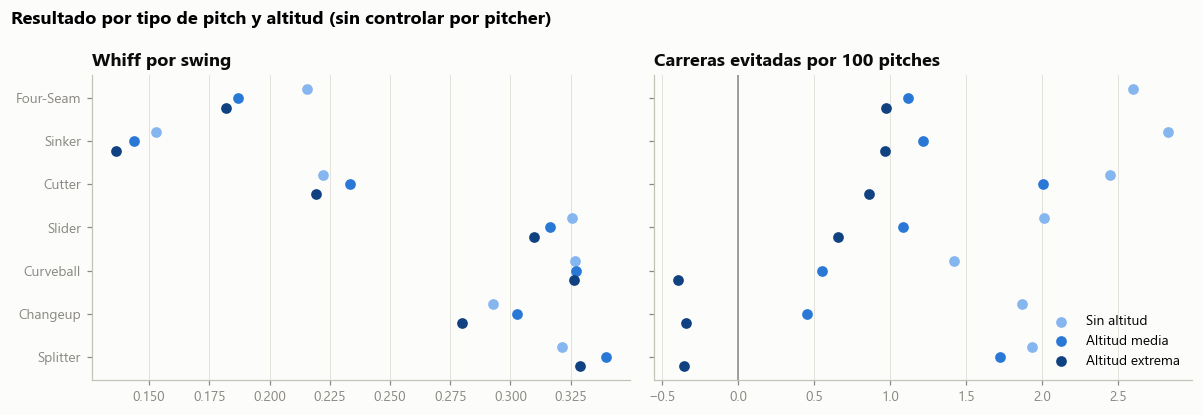

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
y = np.arange(len(PITCH_ORDER))
for ax, col, title in [(axes[0], "whiff/swing", "Whiff por swing"), (axes[1], "RV/100 (pitcher)", "Carreras evitadas por 100 pitches")]:
    for k, cat in enumerate(ALTITUDE_ORDER):
        vals = tab.xs(cat, level=1)[col].reindex(PITCH_ORDER)
        ax.scatter(vals, y + (k - 1) * 0.22, color=ALT_COLORS[cat], s=36, label=ALT_LABELS[cat], zorder=3)
    ax.set_title(title); ax.grid(axis="y", visible=False)
    if col.startswith("RV"):
        ax.axvline(0, color=MUTED, lw=1)
axes[0].set_yticks(y); axes[0].set_yticklabels(PITCH_ORDER); axes[0].invert_yaxis()
axes[1].legend(loc="lower right")
fig.suptitle("Resultado por tipo de pitch y altitud (sin controlar por pitcher)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "03_resultados_pitch_altitud"); plt.show()

## 4. Baseline nulo (criterio del jurado)
"Superar el baseline de modelo nulo (xRunValue promedio por conteo)". Lo medimos con validación por temporada:
entrenar en 2024–2025 y evaluar en 2026. El run value por pitch es muy ruidoso, así que el R² siempre será bajo;
lo importante es **mejorar contra este número** en holdout.

In [10]:
d = df[df.delta_run_exp.notna() & df.usable_stuff]
train, test = d[d.year < 2026], d[d.year == 2026]
glob = train.delta_run_exp.mean()
by_count = train.groupby("count").delta_run_exp.mean()
by_count_pt = train.groupby(["count", "pitch_type"]).delta_run_exp.mean()

def rmse(y, p): return float(np.sqrt(np.mean((y - p) ** 2)))
y = test.delta_run_exp
p_glob = np.full(len(test), glob)
p_count = test["count"].map(by_count).fillna(glob).to_numpy()
p_cpt = pd.MultiIndex.from_frame(test[["count", "pitch_type"]]).map(by_count_pt.to_dict()).to_numpy(dtype=float)
p_cpt = np.where(np.isnan(p_cpt), p_count, p_cpt)
var = np.var(y)
bl = pd.DataFrame({
    "RMSE": [rmse(y, p_glob), rmse(y, p_count), rmse(y, p_cpt)],
    "R²": [1 - np.mean((y - p_glob) ** 2) / var, 1 - np.mean((y - p_count) ** 2) / var, 1 - np.mean((y - p_cpt) ** 2) / var],
}, index=["media global", "media por conteo (baseline del jurado)", "media por conteo × pitch type"])
bl.round(5)

,RMSE,R²
media global,0.27666,-0.00002
media por conteo (baseline del jurado),0.27487,0.01290
media por conteo × pitch type,0.27488,0.01284


## Resumen para el equipo
- La RE de LMB es coherente (monótona en outs y cuenta) y **más alta en altitud**.
- Target principal: `delta_run_exp` con RE de liga. Targets secundarios con las definiciones de arriba (validar
  umbrales de contacto con el equipo).
- Baseline a vencer: RMSE en 2026 del modelo "media por conteo" (tabla anterior).